# ML1_Pipeline + Model

Ce notebook est en plusieurs étapes :
1. Comment charger et préparer les données
2. Comment utiliser correctement train_test_split
3. Comment créer des pipelines de prétraitement
4. Comment implémenter et évaluer un modèle de régression

## Objectif
Prédire l'année de plantation des arbres en utilisant les bonnes pratiques de Machine Learning.

## 1. Import des bibliothèques nécessaires et chargement des données.

Nous utilisons plusieurs bibliothèques essentielles :
- pandas et numpy : pour la manipulation des données
- sklearn : pour le Machine Learning
- matplotlib : pour la visualisation

In [40]:
# Les libraries nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split


Nous chargeons les données depuis le fichier pickle qui contient notre dataset nettoyé.

In [30]:
# Chargement des données depuis le fichier pickle
df = pd.read_pickle('data/arbres_clean.pkl')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 29526 entries, 0 to 31666
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   sous_categorie_desc   29526 non-null  object 
 1   code_parent_desc      29526 non-null  object 
 2   adr_secteur           29526 non-null  int64  
 3   genre_bota            29486 non-null  object 
 4   espece                28313 non-null  object 
 5   stadededeveloppement  27018 non-null  object 
 6   anneedeplantation     29526 non-null  float64
 7   collectivite          29432 non-null  object 
 8   hauteurarbre          23738 non-null  object 
 9   portarbre             18336 non-null  object 
 10  typenature            18336 non-null  object 
 11  latitude              29526 non-null  float64
 12  longitude             29526 non-null  float64
dtypes: float64(3), int64(1), object(9)
memory usage: 3.2+ MB


## 2. Préparation des données pour le ML et séparation train_test

Première étape importante : supprimer les nan de la target puis séparer nos variables explicatives (features) de notre variable cible (target).

Deuxième étape : separation Train-Test

In [16]:
# Suppression des lignes sans année de plantation
# On peut utiliser la méthode *dropna()* pour supprimer les lignes où la anneedeplantation est NaN

# Séperation train/test
# On peut utiliser la méthode *train_test_split()* de scikit-learn pour séparer les données en ensembles d'entraînement et de test

X = df.drop('anneedeplantation', axis=1)
y = df['anneedeplantation']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=28) 

## [Optionnel] Comment on peut remplir les valeurs manquantes sans utiliser le pipeline?

In [17]:
# Remplir les valeurs manquantes avec la valeur la plus fréquente pour chaque colonne concernée
# Valeur la plus fréquente de chaque colonne, calculée sur le train uniquement
modes = X_train.mode().iloc[0]

# Remplissage des NaN (mêmes valeurs appliquées au train et au test)
X_train = X_train.fillna(modes)
X_test = X_test.fillna(modes)

# Vérification
print(X_train.isna().sum().sum(), X_test.isna().sum().sum())

0 0


## [Optionnel] Création de nouvelles variables (Feature Engineering)

In [18]:
# Code

## 3. Création des pipelines de prétraitement

Les pipelines sont essentiels pour :
1. Automatiser les transformations
2. Éviter le data leakage
3. Assurer la cohérence entre train et test

### 3.1 Préparation des données & modèle de base

Nous préparons les données en utilisant un pipeline `scikit-learn` :
- **OneHotEncoder** pour les variables catégorielles
- **StandardScaler** pour les variables numériques
- **LinearRegression** comme modèle de base

In [19]:
# Quelles sont les variables catégorielles et variables numériques ?
# OneHotEncoder ? transforme var cat en 0/1
# StandardScaler ? standardizer les variable moyenne 0 / ecart-type 1


# donner un chiffre a toute variable non numerique
# standardizer les variables non numerique 
force_cat = ["adr_secteur"]
cat_cols = X_train.select_dtypes(include=["object","category"]).columns.tolist() + force_cat
num_cols = X_train.select_dtypes(include=["float"]).columns.tolist()

# ColumnTransformer applique des transformations différentes selon les colonnes, 
# puis assemble le résultat en une seule matrice. 
#On en a besoin parce qu'on ne traite pas une colonne numérique comme une colonne catégorielle.
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
# prep Le ColumnTransformer vu juste avant : scaling des numériques + encodage des catégorielles.
# reg modele qui recoit les données transformées
model = Pipeline([
    ("prep", preprocessor),
    ("reg", LinearRegression()),
])
model.fit(X_train, y_train)






,steps,"[('prep', ...), ('reg', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [20]:
# [OPTIONNEL] Vérification rapide des valeurs manquantes
# Doit etre 0 pour toutes les colonnes pour le train et le test
print(X_train.isna().sum().sum(), X_test.isna().sum().sum())

0 0


## 4. Evaluation avec LinearRegression et plusieurs métriques :
- **MAE** (Mean Absolute Error)
- D'autres?

Ce modèle simple nous servira de point de comparaison pour des modèles plus avancés (comme les arbres de décision ou les forêts aléatoires).

In [21]:
 # On peut utiliser scikit-learn 'mean_absolute_error' pour évaluer la performance du modèle de régression
y_pred = model.predict(X_test)
print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²  :", r2_score(y_test, y_pred))

#MAE = 5.54 : en moynne les predictions se trompent de 5.54 sur l'année de plantation
#MSE = 79.32 : moyenne d'erreurs au carrée 
#RMSE = 8.91 : racide de MSE penalise les grosses erreurs
#R² = 0.76 : modele explique  76% de la variance. 1 ==> parfait / 0 ==> pas mieux que de predire la moyenne


MAE : 5.5429831123864775
MSE : 79.32286683519608
RMSE: 8.906338576272299
R²  : 0.7608088819114092


## 5. Visualisation des prédictions

Visualisons la relation entre les valeurs réelles et prédites :

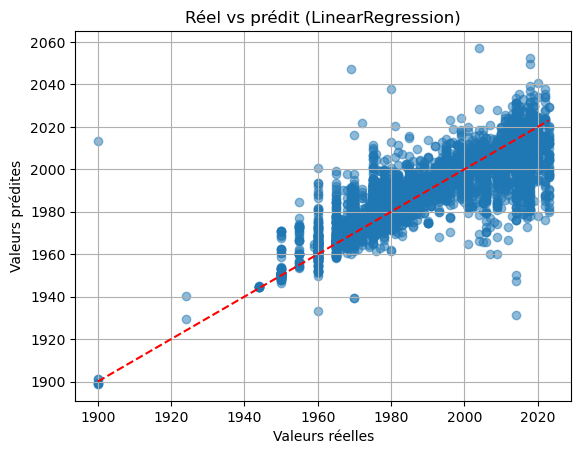

In [39]:
# Code
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Valeurs réelles"); plt.ylabel("Valeurs prédites")
plt.title("Réel vs prédit (LinearRegression)")
plt.grid()
plt.show()

## Comment lire ce graphique

Chaque point est un arbre du jeu de test. L'axe x donne son année de plantation **réelle**, l'axe y l'année **prédite** par le modèle. La ligne rouge en pointillés est la prédiction parfaite (y = x) : plus un point en est proche, meilleure est la prédiction.

## Ce que le graphique montre

- **Le nuage suit globalement la diagonale**, surtout entre 1960 et 2020. C'est cohérent avec  R² de 0,76.
- **Le nuage est plus aplati que la diagonale.** Les arbres anciens sont prédits trop récents, et les arbres récents trop anciens. La régression linéaire tire les prédictions vers la moyenne, car latitude, longitude et secteur ne suffisent pas à distinguer finement les époques.
- **Des prédictions impossibles** : plusieurs points sont prédits entre 2030 et 2060, alors qu'aucun arbre ne peut être planté dans le futur. Une régression linéaire n'a aucune borne. Les arbres et forêts ne peuvent pas prédire hors de la plage des années vues au train, donc ce problème disparaîtra avec eux.
- **Des colonnes verticales de points** vers 1950, 1955, 1960, 1965 : ce sont des années où beaucoup d'arbres ont été plantés d'un coup (une opération d'aménagement, par exemple). Pour une même année réelle, le modèle prédit des valeurs très différentes selon la position.
- **Quelques gros écarts**, comme l'arbre réel 1900 prédit vers 2013. Ce sont eux qui font monter le RMSE (8,91) au-dessus du MAE (5,54).




## Conclusion